# Chapter 5: Linear Models and Regularization

## 1. Introduction

Linear models are machine learning models used to describe relationships between input features and a numerical target. Linear regression is one of the fundamental techniques used for predicting continuous values.

This chapter explores linear regression and regularization techniques using Python and scikit-learn. We will compare ordinary linear regression with Ridge, Lasso, and ElasticNet regression. We will also examine how regularization helps control model complexity and reduce overfitting.

Finally, we will explore polynomial regression and spline interpolation to model relationships that cannot be adequately represented by a straight line.

### Learning Objectives

- Understand the fundamentals of linear regression.
- Implement and evaluate linear regression models.
- Compare Ridge, Lasso, and ElasticNet regression.
- Understand regularization and the bias-variance trade-off.
- Apply polynomial regression and spline interpolation.
- Evaluate regression models using MSE and R².

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Introduction to Linear Models

Linear regression is a supervised learning algorithm that models the relationship between input features and a continuous target variable.

A simple linear regression model can be represented as:

\[
y = \beta_0 + \beta_1x + \epsilon
\]

Where:

- \(y\) is the target value.
- \(x\) is the input feature.
- \(\beta_0\) is the intercept.
- \(\beta_1\) is the coefficient of the feature.
- \(\epsilon\) represents the error term.

For multiple features, the model can be extended to include several coefficients. The model learns these coefficients from the training data and uses them to predict numerical outcomes.

Linear regression is commonly used for predicting prices, sales, demand, and other continuous quantities.

In [2]:
X, y = make_regression(
    n_samples=1000,
    n_features=100,
    n_informative=10,
    noise=20,
    random_state=123
)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

Feature matrix shape: (1000, 100)
Target vector shape: (1000,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 100)
Testing data: (200, 100)


In [4]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression MSE:", mse_linear)
print("Linear Regression R2:", r2_linear)

Linear Regression MSE: 412.19407595093907
Linear Regression R2: 0.9917180692171337


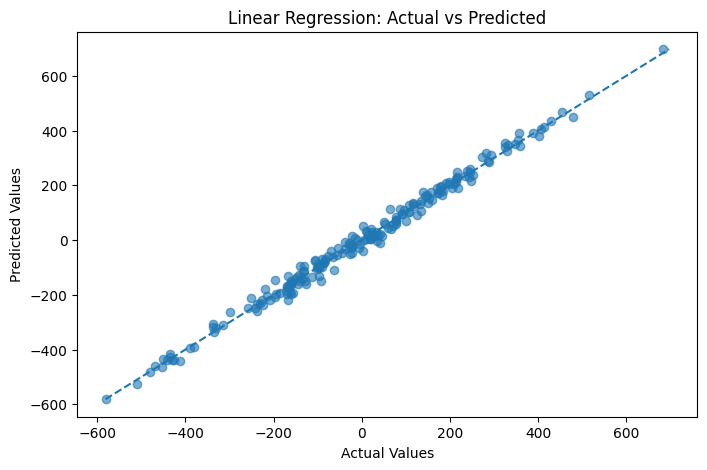

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_linear, alpha=0.6)

minimum = min(y_test.min(), y_pred_linear.min())
maximum = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

## 3. Ridge and Lasso Regression

Ridge and Lasso regression are regularized versions of linear regression. Both techniques add a penalty to the model's objective function to control the magnitude of its coefficients.

### Ridge Regression

Ridge uses L2 regularization. It penalizes the squared values of the coefficients, encouraging them to become smaller without generally forcing them to exactly zero.

### Lasso Regression

Lasso uses L1 regularization. It penalizes the absolute values of the coefficients and can force some coefficients to exactly zero, making it useful for feature selection.

Both methods use the alpha parameter to control regularization strength. A larger alpha generally applies stronger regularization, while a smaller alpha allows the model to fit the training data more freely.

Regularization can improve generalization, especially when the dataset contains correlated features or many predictors.

In [6]:
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0))
])

lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(
        alpha=10.0,
        max_iter=10000,
        tol=0.001
    ))
])

ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

print("Ridge Regression")
print("MSE:", mean_squared_error(y_test, y_pred_ridge))
print("R2:", r2_score(y_test, y_pred_ridge))

print("\nLasso Regression")
print("MSE:", mean_squared_error(y_test, y_pred_lasso))
print("R2:", r2_score(y_test, y_pred_lasso))

Ridge Regression
MSE: 410.0750947443479
R2: 0.991760644442512

Lasso Regression
MSE: 1280.7054173319848
R2: 0.974267670889943


In [7]:
ridge_coef = ridge_model.named_steps["regressor"].coef_
lasso_coef = lasso_model.named_steps["regressor"].coef_

coefficient_comparison = pd.DataFrame({
    "Feature": [f"Feature {i+1}" for i in range(X.shape[1])],
    "Ridge Coefficient": ridge_coef,
    "Lasso Coefficient": lasso_coef
})

print(coefficient_comparison.head(15))

print("\nRidge coefficients equal to zero:",
      np.sum(np.isclose(ridge_coef, 0)))

print("Lasso coefficients equal to zero:",
      np.sum(np.isclose(lasso_coef, 0)))

       Feature  Ridge Coefficient  Lasso Coefficient
0    Feature 1           0.248078          -0.000000
1    Feature 2          -0.681036          -0.000000
2    Feature 3           0.410890          -0.000000
3    Feature 4          39.655498          28.397557
4    Feature 5           0.426168           0.000000
5    Feature 6           2.179113           0.000000
6    Feature 7          -0.626675          -0.000000
7    Feature 8          -0.399872           0.000000
8    Feature 9          -0.258293          -0.000000
9   Feature 10           0.600555          -0.000000
10  Feature 11          -0.651541          -0.000000
11  Feature 12           0.702790           0.000000
12  Feature 13          -1.260385           0.000000
13  Feature 14          -0.392140           0.000000
14  Feature 15          -0.226822           0.000000

Ridge coefficients equal to zero: 0
Lasso coefficients equal to zero: 90


## 4. ElasticNet and Regularization

ElasticNet combines L1 and L2 regularization in a single regression model. It combines the feature-selection behavior of Lasso with the coefficient-shrinking behavior of Ridge.

Two important parameters control ElasticNet:

- **alpha:** Controls the overall strength of regularization.
- **l1_ratio:** Controls the balance between L1 and L2 penalties.

An l1_ratio closer to 1 emphasizes Lasso-like behavior, while a ratio closer to 0 emphasizes Ridge-like behavior.

ElasticNet can be useful when a dataset contains many predictors, especially when some features are correlated. Its performance depends on the dataset and the selected hyperparameters.

In [8]:
elastic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", ElasticNet(
        alpha=0.1,
        l1_ratio=0.5,
        max_iter=10000
    ))
])

elastic_model.fit(X_train, y_train)

y_pred_elastic = elastic_model.predict(X_test)

print("ElasticNet MSE:",
      mean_squared_error(y_test, y_pred_elastic))

print("ElasticNet R2:",
      r2_score(y_test, y_pred_elastic))

ElasticNet MSE: 517.3510185934932
ElasticNet R2: 0.9896052234216325


In [9]:
model_results = []

predictions = {
    "Linear Regression": y_pred_linear,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso,
    "ElasticNet": y_pred_elastic
}

for model_name, prediction in predictions.items():
    model_results.append({
        "Model": model_name,
        "MSE": mean_squared_error(y_test, prediction),
        "R2": r2_score(y_test, prediction)
    })

results_df = pd.DataFrame(model_results)

print(results_df.sort_values("MSE"))

               Model          MSE        R2
1   Ridge Regression   410.075095  0.991761
0  Linear Regression   412.194076  0.991718
3         ElasticNet   517.351019  0.989605
2   Lasso Regression  1280.705417  0.974268


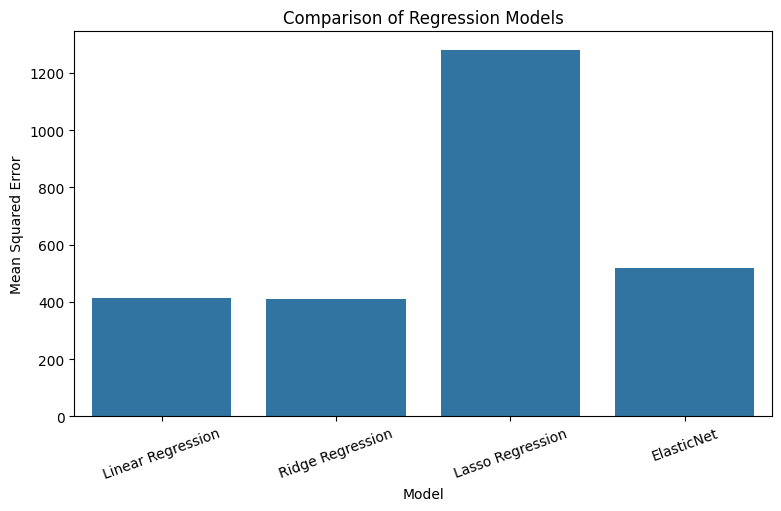

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MSE"
)

plt.title("Comparison of Regression Models")
plt.ylabel("Mean Squared Error")
plt.xticks(rotation=20)
plt.show()

## 5. Regularization Theory and Practice

Regularization is a technique used to reduce overfitting by adding a penalty to a model's objective function. It discourages excessively large coefficients and helps balance model fit with model complexity.

### Overfitting

Overfitting occurs when a model learns the training data too closely, including noise or patterns that do not generalize to new observations.

### Bias-Variance Trade-off

Regularization affects the balance between bias and variance:

- Stronger regularization can simplify the model and reduce variance.
- Excessive regularization can increase bias and cause underfitting.
- The appropriate regularization strength depends on the dataset and should be selected through validation.

The main objective is to find a model that performs well on unseen data rather than simply minimizing training error.

In [11]:
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

alpha_results = []

for alpha in alpha_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=alpha))
    ])

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    alpha_results.append({
        "Alpha": alpha,
        "MSE": mean_squared_error(y_test, prediction),
        "R2": r2_score(y_test, prediction)
    })

alpha_df = pd.DataFrame(alpha_results)

print(alpha_df)

     Alpha          MSE        R2
0    0.001   412.191809  0.991718
1    0.010   412.171419  0.991719
2    0.100   411.968847  0.991723
3    1.000   410.075095  0.991761
4   10.000   403.817450  0.991886
5  100.000  1223.476637  0.975418


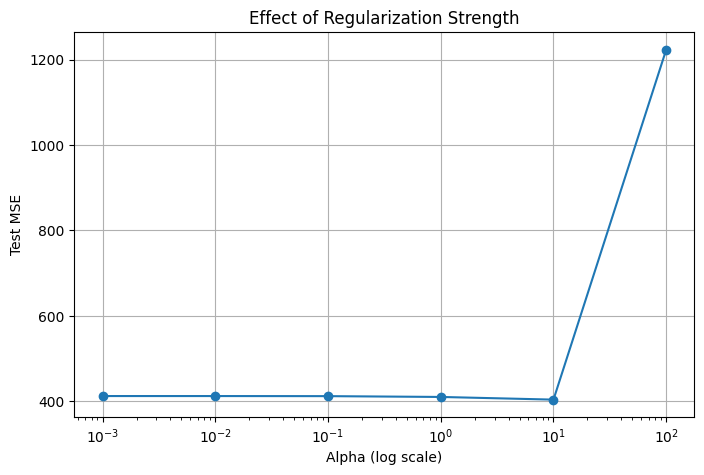

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    alpha_df["Alpha"],
    alpha_df["MSE"],
    marker="o"
)

plt.xscale("log")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Test MSE")
plt.title("Effect of Regularization Strength")
plt.grid(True)
plt.show()

## 6. Regression and Regularization

Ordinary linear regression models linear relationships between input features and the target. However, some datasets contain nonlinear patterns.

Polynomial regression extends linear regression by transforming input features into polynomial terms, such as squared or cubed features. The model remains linear in its coefficients, but it can represent curved relationships.

Spline interpolation provides another approach by constructing flexible piecewise functions. Both techniques can model nonlinear trends, although their complexity should be controlled to avoid overfitting.

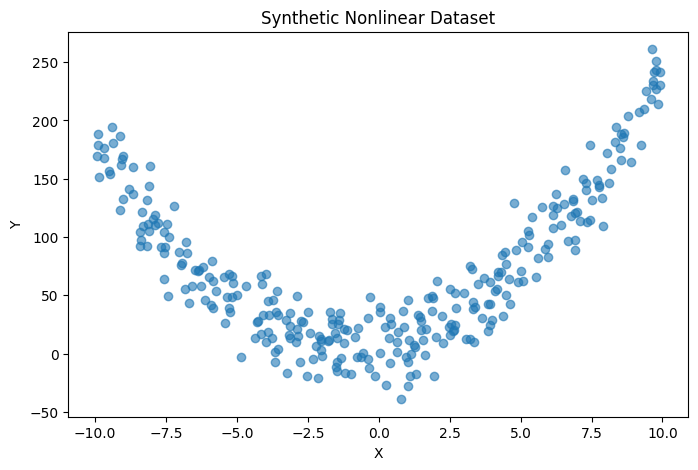

In [13]:
np.random.seed(123)

n_samples = 300

X_nonlinear = np.random.uniform(
    -10, 10, (n_samples, 1)
)

y_nonlinear = (
    2 * X_nonlinear[:, 0] ** 2
    + 3 * X_nonlinear[:, 0]
    + 10
    + np.random.normal(0, 20, n_samples)
)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_nonlinear[:, 0],
    y_nonlinear,
    alpha=0.6
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Synthetic Nonlinear Dataset")
plt.show()

In [14]:
X_train_nl, X_test_nl, y_train_nl, y_test_nl = train_test_split(
    X_nonlinear,
    y_nonlinear,
    test_size=0.2,
    random_state=123
)

poly_model = Pipeline([
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0))
])

poly_model.fit(X_train_nl, y_train_nl)

y_pred_poly = poly_model.predict(X_test_nl)

print("Polynomial Regression MSE:",
      mean_squared_error(y_test_nl, y_pred_poly))

print("Polynomial Regression R2:",
      r2_score(y_test_nl, y_pred_poly))

Polynomial Regression MSE: 362.84813884986056
Polynomial Regression R2: 0.9183673235795324


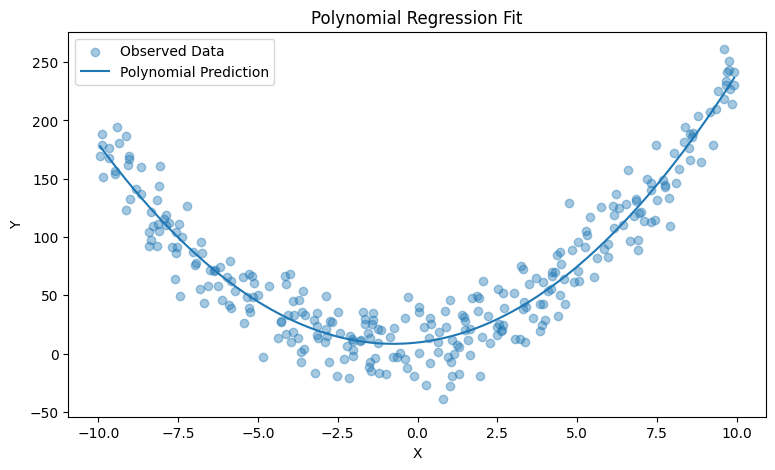

In [15]:
X_sorted = np.linspace(
    X_nonlinear.min(),
    X_nonlinear.max(),
    300
).reshape(-1, 1)

y_sorted_pred = poly_model.predict(X_sorted)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_nonlinear[:, 0],
    y_nonlinear,
    alpha=0.4,
    label="Observed Data"
)

plt.plot(
    X_sorted[:, 0],
    y_sorted_pred,
    label="Polynomial Prediction"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Polynomial Regression Fit")
plt.legend()
plt.show()

In [16]:
spline_model = Pipeline([
    ("spline", SplineTransformer(
        n_knots=5,
        degree=3
    )),
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0))
])

spline_model.fit(X_train_nl, y_train_nl)

y_pred_spline = spline_model.predict(X_test_nl)

print("Spline Regression MSE:",
      mean_squared_error(y_test_nl, y_pred_spline))

print("Spline Regression R2:",
      r2_score(y_test_nl, y_pred_spline))

Spline Regression MSE: 362.62874079285405
Spline Regression R2: 0.9184166832115032


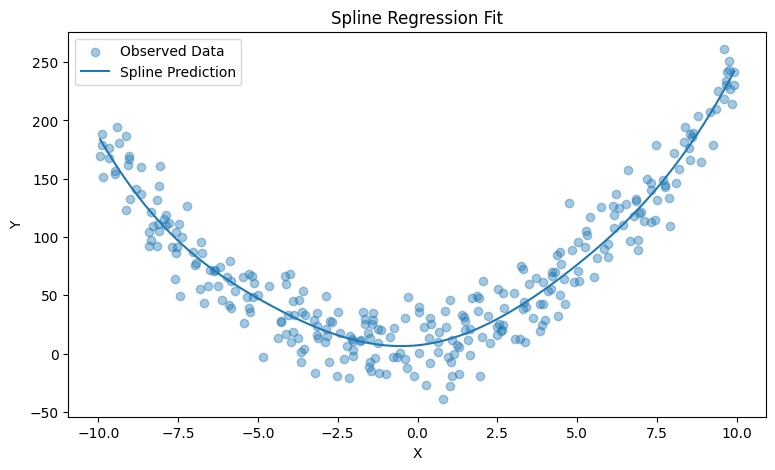

In [17]:
y_spline_pred = spline_model.predict(X_sorted)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_nonlinear[:, 0],
    y_nonlinear,
    alpha=0.4,
    label="Observed Data"
)

plt.plot(
    X_sorted[:, 0],
    y_spline_pred,
    label="Spline Prediction"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Spline Regression Fit")
plt.legend()
plt.show()

## 7. Practical Exercises

### Exercise 1: Implementing Ridge Regression

Generate a synthetic regression dataset, split it into training and testing sets, train a Ridge regression model, and evaluate its performance using MSE and R².

### Exercise 2: Implementing Lasso Regression

Train a Lasso regression model on a suitable dataset. Evaluate its performance and examine whether some coefficients become zero.

### Exercise 3: Implementing ElasticNet Regression

Train an ElasticNet model and experiment with different values of alpha and l1_ratio. Compare the results with Ridge and Lasso regression.

### Additional Exploration

- Compare actual and predicted target values.
- Examine the effect of regularization strength on model performance.
- Compare polynomial regression and spline regression on nonlinear data.
- Explain which model performs best on the testing data and why.

## 8. Conclusion

In this chapter, we explored linear models and regularization techniques using scikit-learn. We implemented linear regression and compared it with Ridge, Lasso, and ElasticNet regression.

We learned that Ridge reduces the magnitude of model coefficients, while Lasso can set some coefficients to zero. ElasticNet combines both regularization approaches. We also examined how regularization strength affects model complexity and the balance between bias and variance.

Finally, we applied polynomial regression and spline transformation to model nonlinear relationships.

The experiments demonstrate that model selection should be based on appropriate evaluation metrics and performance on unseen data. Regularization and nonlinear feature transformations can improve predictions when selected appropriately for the characteristics of the dataset.